# AICS-202 | Laboratory 03
## Training Data Poisoning and Dataset Integrity
Course module: 3 | Suggested duration: 4 hours

**Objective:** measure how deliberately corrupted labels in a local training dataset affect a supervised model. This lab never changes external datasets or services.

**Scope:** simple random label corruption is an introductory poisoning simulation, not a realistic targeted backdoor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


Corruption 0%: 0 labels changed | Clean test accuracy 0.962
Corruption 5%: 67 labels changed | Clean test accuracy 0.960
Corruption 10%: 135 labels changed | Clean test accuracy 0.958
Corruption 20%: 269 labels changed | Clean test accuracy 0.933
Corruption 30%: 404 labels changed | Clean test accuracy 0.924
Corruption 40%: 539 labels changed | Clean test accuracy 0.893
Corruption 50%: 674 labels changed | Clean test accuracy 0.860
Corruption 60%: 808 labels changed | Clean test accuracy 0.840
Corruption 70%: 943 labels changed | Clean test accuracy 0.676
Corruption 80%: 1078 labels changed | Clean test accuracy 0.542
Corruption 90%: 1212 labels changed | Clean test accuracy 0.087
Corruption 100%: 1347 labels changed | Clean test accuracy 0.007


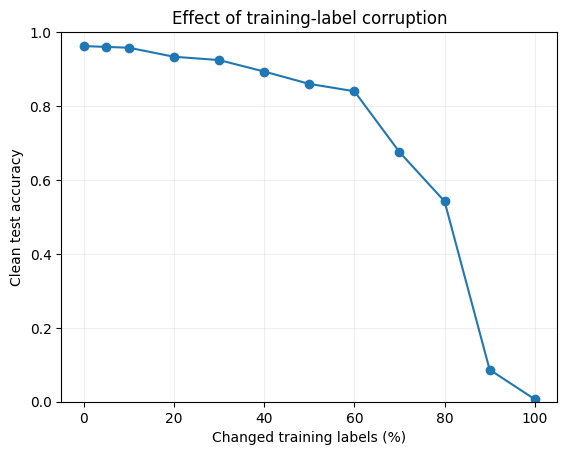

In [5]:
from sklearn.metrics import confusion_matrix
rng = np.random.default_rng(2026)
corruption_levels = [0.00, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
records = []
for fraction in corruption_levels:
    labels_changed = y_train.copy()
    n = round(len(labels_changed)*fraction)
    selected = rng.choice(len(labels_changed), size=n, replace=False)
    # Replace with a *different* label; this simulates integrity compromise.
    labels_changed[selected] = (labels_changed[selected] + rng.integers(1, 10, size=n)) % 10
    tested_model = build_model(X_train, labels_changed)
    accuracy = accuracy_score(y_test, tested_model.predict(X_test))
    records.append((fraction, n, accuracy))
    print(f'Corruption {fraction:.0%}: {n} labels changed | Clean test accuracy {accuracy:.3f}')
plt.plot([r[0]*100 for r in records], [r[2] for r in records], 'o-')
plt.xlabel('Changed training labels (%)'); plt.ylabel('Clean test accuracy')
plt.title('Effect of training-label corruption');plt.ylim(0,1);plt.grid(alpha=.2);plt.show()

### Part B - Create a data integrity checklist
Prepare a controls table for dataset provenance, cryptographic hashes, label audits, role-restricted writes, staged approval, and anomaly review.

**Student exercises:**
- Explain why training data is a security asset.
- Compare control results and explain any non-monotonic accuracy changes.
- Propose three technical and two procedural safeguards.

**Deliverables:** plot, results table, explanation and a signed-off integrity checklist for this hypothetical dataset.